In [2]:
import torch
import numpy as np

In [11]:
data= [[1,2,],[3,4]]
x_data = torch.tensor(data)

In [12]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

In [13]:
x_ones = torch.ones_like(x_data)
print(f'{x_ones}')

x_rand = torch.rand_like(x_data,dtype=torch.float)
print(f'{x_rand}')

tensor([[1, 1],
        [1, 1]])
tensor([[0.6084, 0.0979],
        [0.6429, 0.9602]])


In [14]:
shape = (2,3,)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random :  {rand_tensor}\n")
print(f"Ones : {ones_tensor}\n")
print(f"Zeros : {zeros_tensor}")

Random :  tensor([[0.9423, 0.8294, 0.3061],
        [0.4485, 0.3048, 0.6477]])

Ones : tensor([[1., 1., 1.],
        [1., 1., 1.]])

Zeros : tensor([[0., 0., 0.],
        [0., 0., 0.]])


In [40]:
t1 = torch.cat([tensor,tensor,tensor], dim = 1)
t2 = torch.cat([tensor,tensor,tensor],dim = 0)

In [41]:
print(t1)

tensor([[0.8380, 0.4920, 0.3659, 0.2996, 0.8380, 0.4920, 0.3659, 0.2996, 0.8380,
         0.4920, 0.3659, 0.2996],
        [0.3640, 0.7102, 0.9330, 0.4972, 0.3640, 0.7102, 0.9330, 0.4972, 0.3640,
         0.7102, 0.9330, 0.4972],
        [0.2131, 0.1839, 0.4175, 0.9233, 0.2131, 0.1839, 0.4175, 0.9233, 0.2131,
         0.1839, 0.4175, 0.9233]])


In [42]:
print(t2)

tensor([[0.8380, 0.4920, 0.3659, 0.2996],
        [0.3640, 0.7102, 0.9330, 0.4972],
        [0.2131, 0.1839, 0.4175, 0.9233],
        [0.8380, 0.4920, 0.3659, 0.2996],
        [0.3640, 0.7102, 0.9330, 0.4972],
        [0.2131, 0.1839, 0.4175, 0.9233],
        [0.8380, 0.4920, 0.3659, 0.2996],
        [0.3640, 0.7102, 0.9330, 0.4972],
        [0.2131, 0.1839, 0.4175, 0.9233]])


In [45]:
# This computes the matrix multiplication between two tensors. y1, y2, y3 will have the same value
# ``tensor.T`` returns the transpose of a tensor
y1 = tensor @ tensor.T
y2 = tensor.matmul(tensor.T)

y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)


# This computes the element-wise product. z1, z2, z3 will have the same value
z1 = tensor * tensor
z2 = tensor.mul(tensor)

z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)

tensor([[0.7022, 0.2421, 0.1339, 0.0898],
        [0.1325, 0.5044, 0.8705, 0.2472],
        [0.0454, 0.0338, 0.1743, 0.8525]])

In [46]:
print(f"{tensor} \n")
tensor.add_(5)
print(tensor)

tensor([[0.8380, 0.4920, 0.3659, 0.2996],
        [0.3640, 0.7102, 0.9330, 0.4972],
        [0.2131, 0.1839, 0.4175, 0.9233]]) 

tensor([[5.8380, 5.4920, 5.3659, 5.2996],
        [5.3640, 5.7102, 5.9330, 5.4972],
        [5.2131, 5.1839, 5.4175, 5.9233]])


In [48]:
t = torch.ones(5)
print(f"t: {t}")
n = t.numpy()
print(f"{n}")

t: tensor([1., 1., 1., 1., 1.])
[1. 1. 1. 1. 1.]


In [49]:
t.add_(1)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


In [50]:
n = np.ones(5)
t = torch.from_numpy(n)

In [51]:
np.add(n, 1, out=n)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
n: [2. 2. 2. 2. 2.]


DataSet & DataLoaders

In [15]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [16]:
training_data = datasets.FashionMNIST(
    root = 'data', train = True, download = True,
    transform = ToTensor()
)

test_data = datasets.FashionMNIST(
    root = 'data', train = False , download = True,
    transform = ToTensor()
)

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 7.04MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 55.8MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.3MB/s]


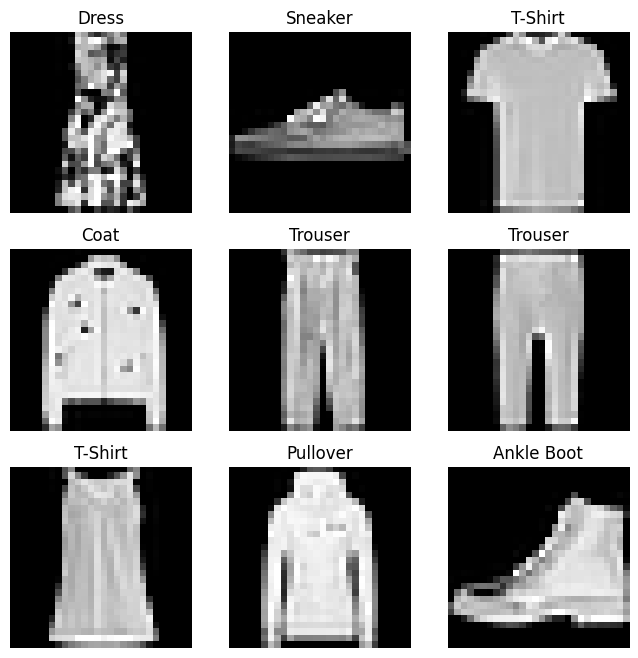

In [20]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [31]:
import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [36]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

In [38]:
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

TypeError: 'DataLoader' object is not subscriptable